# Chapter 12 : Deep Computer Vision Using Convolutional Neural Networks

In [2]:
import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchmetrics
import torchvision
import torchvision.transforms.v2 as T
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets

In [3]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device

'mps'

In [4]:
def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric.update(y_pred, y_batch)
    return metric.compute()

def train(model, optimizer, loss_fn, metric, train_loader, valid_loader, n_epochs):
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(metric.compute().item())
        history["valid_metrics"].append(
            evaluate_tm(model, valid_loader, metric).item())
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")
    return history

**Exercice 1 : Build your own CNN from scratch and try to achieve the highest possible accuracy on MNIST**

In [ ]:
train_transform_mnist = T.Compose([
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    T.Normalize(mean=[0.1307], std=[0.3081]),
])

eval_transform_mnist = T.Compose([
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(mean=[0.1307], std=[0.3081]),
])

train_full = torchvision.datasets.MNIST("datasets", train=True, download=True, transform=train_transform_mnist)
valid_full = torchvision.datasets.MNIST("datasets", train=True, download=True, transform=eval_transform_mnist)
test_data  = torchvision.datasets.MNIST("datasets", train=False, download=True, transform=eval_transform_mnist)

perm = torch.randperm(60_000, generator=torch.Generator().manual_seed(42)).tolist()
train_data = Subset(train_full, perm[:55_000])
valid_data = Subset(valid_full, perm[55_000:])

train_loader = DataLoader(train_data, batch_size=128, shuffle=True, num_workers=2)
valid_loader = DataLoader(valid_data, batch_size=256)
test_loader  = DataLoader(test_data, batch_size=256)

In [ ]:
class AlexNetLike(nn.Module):
    def __init__(self):
        super().__init__()
        layers = [
            nn.Conv2d(in_channels=1, out_channels=96, kernel_size=3, stride=1, padding='same'), nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=0),
            nn.Conv2d(in_channels=96, out_channels=256, kernel_size=5, stride=1, padding='same'), nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=0),
            nn.Conv2d(in_channels=256, out_channels=384, kernel_size=3, stride=1, padding='same'), nn.ReLU(),
            nn.Conv2d(in_channels=384, out_channels=384, kernel_size=3, stride=1, padding='same'), nn.ReLU(),
            nn.Conv2d(in_channels=384, out_channels=256, kernel_size=3, stride=1, padding='same'), nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=0),
            nn.Flatten(),
            nn.LazyLinear(1024), nn.Dropout(0.5), nn.ReLU(),
            nn.LazyLinear(1024), nn.Dropout(0.5), nn.ReLU(),
            nn.LazyLinear(10)
        ]
        self.alexnetlike = nn.Sequential(*layers)

    def forward(self, inputs):
        return self.alexnetlike(inputs)

In [28]:
def use_he_init(module):
    if isinstance(module, (nn.Linear, nn.Conv2d)):
        nn.init.kaiming_uniform_(module.weight, nonlinearity="relu")
        nn.init.zeros_(module.bias)

In [ ]:
# Instanciation et initialisation du modèle

model = AlexNetLike().to(device)
model(torch.randn(2, 1, 28, 28, device=device))   # initialise les LazyLinear
model.apply(use_he_init)

AlexNetLike(
  (alexnetlike): Sequential(
    (0): Conv2d(1, 96, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(96, 256, kernel_size=(5, 5), stride=(1, 1), padding=same)
    (4): ReLU()
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(256, 384, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (7): ReLU()
    (8): Conv2d(384, 384, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (9): ReLU()
    (10): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (11): ReLU()
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (13): Flatten(start_dim=1, end_dim=-1)
    (14): Linear(in_features=1024, out_features=1024, bias=True)
    (15): Dropout(p=0.5, inplace=False)
    (16): ReLU()
    (17): Linear(in_features=1024, out_features=1024, bias=True)
    (18): Dropout(p=0.

In [ ]:
# Entrainement 1 du modèle, lr=1e-3

n_epochs = 5
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
xentropy = nn.CrossEntropyLoss()
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=10).to(device)
history = train(model, optimizer, xentropy, accuracy,
                train_loader, valid_loader, n_epochs)

Epoch 1/5, train loss: 0.4785, train metric: 0.8741, valid metric: 0.9786
Epoch 2/5, train loss: 0.1069, train metric: 0.9701, valid metric: 0.9788
Epoch 3/5, train loss: 0.0849, train metric: 0.9770, valid metric: 0.9850
Epoch 4/5, train loss: 0.0757, train metric: 0.9790, valid metric: 0.9894
Epoch 5/5, train loss: 0.0684, train metric: 0.9818, valid metric: 0.9890


In [ ]:
# Entrainement 2 du modèle, lr=1e-4

n_epochs = 10
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
history = train(model, optimizer, xentropy, accuracy,
                train_loader, valid_loader, n_epochs)

Epoch 1/10, train loss: 0.0358, train metric: 0.9907, valid metric: 0.9938
Epoch 2/10, train loss: 0.0310, train metric: 0.9916, valid metric: 0.9940
Epoch 3/10, train loss: 0.0274, train metric: 0.9929, valid metric: 0.9942
Epoch 4/10, train loss: 0.0246, train metric: 0.9930, valid metric: 0.9942
Epoch 5/10, train loss: 0.0233, train metric: 0.9933, valid metric: 0.9944
Epoch 6/10, train loss: 0.0209, train metric: 0.9938, valid metric: 0.9942
Epoch 7/10, train loss: 0.0219, train metric: 0.9941, valid metric: 0.9944
Epoch 8/10, train loss: 0.0206, train metric: 0.9935, valid metric: 0.9948
Epoch 9/10, train loss: 0.0195, train metric: 0.9945, valid metric: 0.9946
Epoch 10/10, train loss: 0.0181, train metric: 0.9945, valid metric: 0.9942


In [ ]:
# Résultat final sur jeu de test
test_accuracy = evaluate_tm(model, test_loader, accuracy)
print(test_accuracy)

tensor(0.9961, device='mps:0')


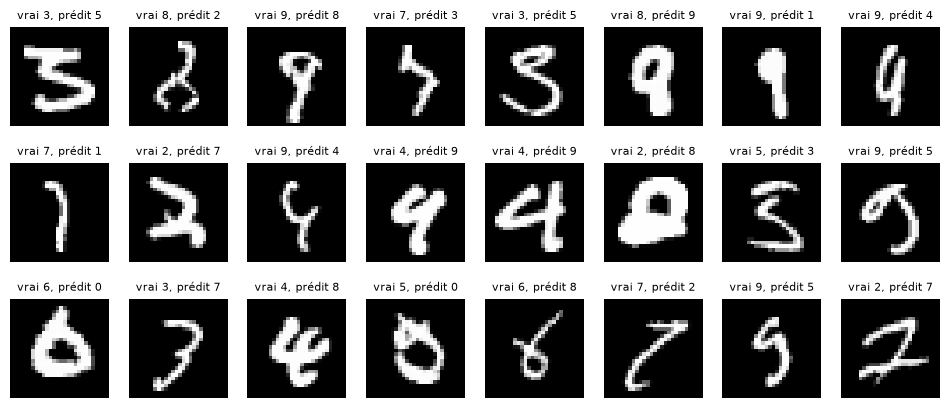

In [ ]:
# Visualisation des erreurs
model.eval()
errors = []
with torch.no_grad():
    for X, y in test_loader:
        pred = model(X.to(device)).argmax(1).cpu()
        wrong = pred != y
        errors += [(X[i], y[i].item(), pred[i].item()) for i in wrong.nonzero().flatten()]

fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for ax, (img, true, pred) in zip(axes.flat, errors):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"vrai {true}, prédit {pred}", fontsize=8)
    ax.axis("off")
plt.show()

**Exercice 2 : Use transfert learning for large image classification**

In [ ]:
# Telechargement du modèle et de ses poids
weights = torchvision.models.EfficientNet_V2_S_Weights.IMAGENET1K_V1
model = torchvision.models.efficientnet_v2_s(weights=weights).to(device)

# Transformations attendues par le modèle
eval_transform_hymenoptera = weights.transforms()
print(eval_transform_hymenoptera)   # affiche resize_size, crop_size, interpolation, mean, std

ImageClassification(
    crop_size=[384]
    resize_size=[384]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [ ]:
# Preprocessing (avec augmentation pour l'entraînement)
data_transforms_hymenoptera = {
    'train': T.Compose([
        T.RandomResizedCrop(eval_transform_hymenoptera.crop_size[0]),
        T.RandomHorizontalFlip(),
        T.ToImage(),
        T.ToDtype(torch.float32, scale=True),
        T.Normalize(eval_transform_hymenoptera.mean, eval_transform_hymenoptera.std),
    ]),
    'val': eval_transform_hymenoptera,
}

# Chargement des jeux de données
data_dir = 'datasets/hymenoptera_data'
train_set = datasets.ImageFolder(os.path.join(data_dir, 'train'), data_transforms_hymenoptera['train'])
val_full  = datasets.ImageFolder(os.path.join(data_dir, 'val'),   data_transforms_hymenoptera['val'])

# Découpe stratifiée du jeu 'val' : 100 validation + 53 test
val_idx, test_idx = train_test_split(
    range(len(val_full)),
    test_size=53,
    stratify=val_full.targets,   # garde les proportions de classes
    random_state=42,             # coupure identique à chaque exécution
)

image_datasets = {
    'train': train_set,
    'val':   Subset(val_full, val_idx),
    'test':  Subset(val_full, test_idx),
}

dataloaders = {
    'train': DataLoader(image_datasets['train'], batch_size=4, shuffle=True,  num_workers=4),
    'val':   DataLoader(image_datasets['val'],   batch_size=4, shuffle=False, num_workers=4),
    'test':  DataLoader(image_datasets['test'],  batch_size=4, shuffle=False, num_workers=4),
}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val', 'test']}
class_names = train_set.classes

print("\nTaille des datasets : ")
print(dataset_sizes)

print("\nVérification de la stratification : ")
for name in ['val', 'test']:
    labels = [val_full.targets[i] for i in image_datasets[name].indices]
    counts = {class_names[c]: labels.count(c) for c in range(len(class_names))}
    print(name, counts)

Using mps device

Taille des datasets : 
{'train': 244, 'val': 100, 'test': 53}

Vérification de la stratification : 
val {'ants': 46, 'bees': 54}
test {'ants': 24, 'bees': 29}


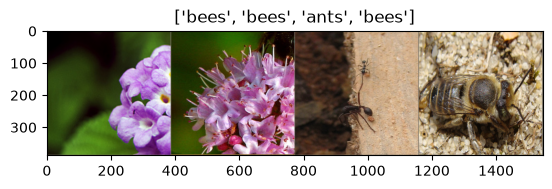

In [ ]:
# Visualisation de données d'entrainement (avec l'augmentation)

def imshow(inp, title=None):
    """Display image for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = eval_transform_hymenoptera.mean
    std = eval_transform_hymenoptera.std
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)  # pause a bit so that plots are updated

inputs, classes = next(iter(dataloaders['train']))
out = torchvision.utils.make_grid(inputs)

imshow(out, title=[class_names[x] for x in classes])

In [8]:
[name for name, child in model.named_children()]

['features', 'avgpool', 'classifier']

In [9]:
model.classifier

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)

In [ ]:
# On remplace la "tête" du modèle pour en faire un classifier à 2 classes. 

n_classes = 2
model.classifier[1] = nn.Linear(1280, n_classes, bias=True).to(device)

In [ ]:
# On commence par entrainer uniquement la tête du modèle

for param in model.parameters():
    param.requires_grad = False

for param in model.classifier.parameters():
    param.requires_grad = True

In [12]:
n_epochs = 5
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
xentropy = nn.CrossEntropyLoss()
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=2).to(device)

history = train(model, optimizer, xentropy, accuracy, dataloaders['train'], dataloaders['val'],
          n_epochs)

Epoch 1/5, train loss: 0.6763, train metric: 0.5656, valid metric: 0.8000
Epoch 2/5, train loss: 0.6159, train metric: 0.7623, valid metric: 0.8700
Epoch 3/5, train loss: 0.5672, train metric: 0.7746, valid metric: 0.8700
Epoch 4/5, train loss: 0.5166, train metric: 0.8525, valid metric: 0.8900
Epoch 5/5, train loss: 0.4785, train metric: 0.8607, valid metric: 0.9000


In [13]:
for i, block in enumerate(model.features):
    print(i, block.__class__.__name__)

0 Conv2dNormActivation
1 Sequential
2 Sequential
3 Sequential
4 Sequential
5 Sequential
6 Sequential
7 Conv2dNormActivation


In [ ]:
# On dégèle les poids des 3 dernières couches du modèle (hors classifier) pour entrainement

for param in model.features[-3:].parameters():
    param.requires_grad = True

In [15]:
n_epochs = 5
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
history = train(model, optimizer, xentropy, accuracy, dataloaders['train'], dataloaders['val'],
          n_epochs)

Epoch 1/5, train loss: 0.4253, train metric: 0.8607, valid metric: 0.9400
Epoch 2/5, train loss: 0.3591, train metric: 0.8648, valid metric: 0.9400
Epoch 3/5, train loss: 0.3168, train metric: 0.8689, valid metric: 0.9300
Epoch 4/5, train loss: 0.3036, train metric: 0.8607, valid metric: 0.9300
Epoch 5/5, train loss: 0.2462, train metric: 0.9057, valid metric: 0.9300


In [ ]:
# On entraine la totalité du modèle (avec un lr faible)

for param in model.features.parameters():
    param.requires_grad = True

n_epochs = 2
optimizer = torch.optim.AdamW(model.parameters(), lr=8e-6)
history = train(model, optimizer, xentropy, accuracy, dataloaders['train'], dataloaders['val'],
          n_epochs)

Epoch 1/2, train loss: 0.2888, train metric: 0.8811, valid metric: 0.9400
Epoch 2/2, train loss: 0.2717, train metric: 0.8689, valid metric: 0.9500


In [ ]:
# Test final

test_accuracy = evaluate_tm(model, dataloaders['test'], accuracy)
print(test_accuracy)

tensor(0.9623, device='mps:0')


2 erreurs sur 53 images


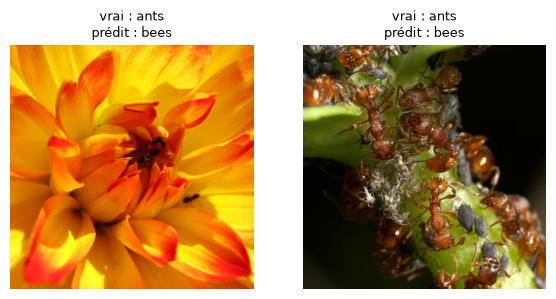

In [ ]:
# Visualisation des erreurs sur le jeu de test

mean = torch.tensor(eval_transform_hymenoptera.mean).view(3, 1, 1)
std = torch.tensor(eval_transform_hymenoptera.std).view(3, 1, 1)

model.eval()
errors = []
with torch.no_grad():
    for X, y in dataloaders['test']:
        pred = model(X.to(device)).argmax(1).cpu()
        wrong = (pred != y).nonzero().flatten()
        errors += [(X[i], y[i].item(), pred[i].item()) for i in wrong]

print(f"{len(errors)} erreurs sur {dataset_sizes['test']} images")

if errors:
    n_cols = min(len(errors), 4)
    n_rows = (len(errors) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")                               # cache aussi les cases inutilisées
    for ax, (img, true, pred) in zip(axes.flat, errors):
        img = (img * std + mean).clamp(0, 1)         # annule la normalisation
        ax.imshow(img.permute(1, 2, 0))              # (3, H, W) -> (H, W, 3)
        ax.set_title(f"vrai : {class_names[true]}\nprédit : {class_names[pred]}", fontsize=9)
    plt.tight_layout()
    plt.show()